In [34]:
# %% 1. Import & baca data
import pandas as pd

data = pd.read_csv(r"C:\Users\s2\Documents\RKI\BRFSS\brfss2025.csv")
print(f"Ukuran awal: {data.shape}")

# %% 2. Filter dulu: hanya DIABETE4 == 1
print(data['DIABETE4'].value_counts(dropna=False))

data = data[data['DIABETE4'] == 1].copy()
data = data.reset_index(drop=True)

print(f"Ukuran setelah filter: {data.shape}")
print(data['DIABETE4'].value_counts())

Ukuran awal: (356158, 283)
DIABETE4
3.0    290712
1.0     51827
4.0     10166
2.0      2671
7.0       580
9.0       196
NaN         6
Name: count, dtype: int64
Ukuran setelah filter: (51827, 283)
DIABETE4
1.0    51827
Name: count, dtype: int64


In [35]:
data

,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,_VEGRES1,_FRUTSU1,_VEGESU1,_FRTLT1A,_VEGLT1A,_FRT16A,_VEG23A,_FRUITE1,_VEGETE1,_AIDTST4
0,1.0,1.0,4072025,4,7,2025,1100.0,2025000002,2.025000e+09,1.0,...,1.000000e+00,107.0,145.0,1.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
1,1.0,1.0,4042025,4,4,2025,1100.0,2025000003,2.025000e+09,1.0,...,1.000000e+00,72.0,144.0,2.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
2,1.0,1.0,4082025,4,8,2025,1100.0,2025000004,2.025000e+09,1.0,...,1.000000e+00,300.0,63.0,1.0,2.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
3,1.0,1.0,4042025,4,4,2025,1100.0,2025000022,2.025000e+09,1.0,...,1.000000e+00,57.0,125.0,2.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
4,1.0,1.0,4042025,4,4,2025,1100.0,2025000023,2.025000e+09,1.0,...,5.397605e-79,100.0,NaN,1.0,9.0,1.0,1.0,5.397605e-79,1.000000e+00,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51822,72.0,12.0,2232026,2,23,2026,1100.0,2025003827,2.025004e+09,NaN,...,1.000000e+00,14.0,12.0,2.0,2.0,1.0,1.0,5.397605e-79,5.397605e-79,1.0
51823,72.0,12.0,2232026,2,23,2026,1100.0,2025003829,2.025004e+09,NaN,...,1.000000e+00,100.0,203.0,1.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,1.0
51824,72.0,12.0,2142026,2,14,2026,1100.0,2025003839,2.025004e+09,NaN,...,1.000000e+00,7.0,46.0,2.0,2.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
51825,72.0,12.0,2202026,2,20,2026,1100.0,2025003840,2.025004e+09,NaN,...,1.000000e+00,129.0,228.0,1.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0


In [36]:
# %% 3. Cek missing value (dihitung dari data diabetes saja)
missing = data.isnull().sum()
missing_pct = (missing / len(data)) * 100

missing_df = pd.DataFrame({
    'jumlah_kosong': missing,
    'persen_kosong': missing_pct.round(2)
})
missing_df = (missing_df[missing_df['jumlah_kosong'] > 0]
              .sort_values('persen_kosong', ascending=False))

print(f"Total fitur           : {data.shape[1]}")
print(f"Fitur yang ada kosong : {len(missing_df)}")
print(missing_df.head(20))

Total fitur           : 283
Fitur yang ada kosong : 197
          jumlah_kosong  persen_kosong
COLGHOUS          51825         100.00
PREDIAB2          51827         100.00
PDIABTS1          51827         100.00
ICFQSTVR          51827         100.00
CCLGHOUS          51785          99.92
HPVADSHT          51724          99.80
CSRVCTL2          51671          99.70
NOBCUSE9          51663          99.68
USEMRJN4          51473          99.32
CASTHNO2          51461          99.29
TYPCNT10          51445          99.26
CSRVINST          51432          99.24
MENTECIG          51409          99.19
CSRVDEIN          51287          98.96
CSRVCLIN          51287          98.96
CSRVDOC1          51284          98.95
CSRVRTRN          51285          98.95
CSRVSUM           51285          98.95
CSRVINSR          51285          98.95
PFPPRVN4          51273          98.93


In [37]:
# %% 4. Hapus fitur dengan missing value > 15%
cols_to_drop = missing_pct[missing_pct >= 20].index

print(f"Jumlah fitur yang dihapus: {len(cols_to_drop)}")
print(missing_pct[cols_to_drop].sort_values(ascending=False).head(20))

data = data.drop(columns=cols_to_drop)
print(f"Sisa fitur: {data.shape[1]}")


Jumlah fitur yang dihapus: 145
PREDIAB2    100.000000
PDIABTS1    100.000000
ICFQSTVR    100.000000
COLGHOUS     99.996141
CCLGHOUS     99.918961
HPVADSHT     99.801262
CSRVCTL2     99.698999
NOBCUSE9     99.683563
USEMRJN4     99.316958
CASTHNO2     99.293804
TYPCNT10     99.262932
CSRVINST     99.237849
MENTECIG     99.193471
CSRVDEIN     98.958072
CSRVCLIN     98.958072
CSRVINSR     98.954213
CSRVRTRN     98.954213
CSRVSUM      98.954213
CSRVDOC1     98.952284
PFPPRVN4     98.931059
dtype: float64
Sisa fitur: 138


In [38]:
sisa = data.isnull().sum()
sisa_pct = (sisa / len(data) * 100).round(2)

sisa_df = pd.DataFrame({'jumlah': sisa, 'persen': sisa_pct})
sisa_df = sisa_df[sisa_df['jumlah'] > 0].sort_values('persen', ascending=False)

print(f"Fitur yang masih punya kosong: {len(sisa_df)} dari {data.shape[1]}")
print(sisa_df)

Fitur yang masih punya kosong: 52 dari 138
          jumlah  persen
_VEGESU1    7691   14.84
_FRUTSU1    6608   12.75
VEGEDA2_    6217   12.00
POTADA1_    6081   11.73
FRUTDA2_    5847   11.28
GRENDA1_    5719   11.03
FRNCHDA_    5679   10.96
FTJUDA2_    5638   10.88
VEGETAB2    5225   10.08
POTATOE1    5095    9.83
FRENCHF1    4987    9.62
FVGREEN1    4864    9.39
FRUITJU2    4745    9.16
FRUIT2      4621    8.92
_AIDTST4    4505    8.69
HIVTST7     4505    8.69
_BMI5       4231    8.16
_BMI5CAT    4231    8.16
TETANUS1    4186    8.08
CHOLMED3    3910    7.54
WTKG3       3741    7.22
PNEUVAC4    3358    6.48
FLUSHOT7    3220    6.21
SLEPTIM1    3068    5.92
ALCDAY4     3034    5.85
HTIN4       2693    5.20
ECIGNOW3    2592    5.00
USENOW3     2428    4.68
TOLDHI3     2428    4.68
_RFCHOL3    2428    4.68
HTM4        2348    4.53
SMOKE100    2344    4.52
DIFFALON    2022    3.90
DIFFDRES    1916    3.70
DIFFWALK    1825    3.52
DECIDE      1705    3.29
BLIND       1593    3.07
DEAF   

In [39]:
data.isna().sum()

_STATE         0
FMONTH         0
IDATE          0
IMONTH         0
IDAY           0
IYEAR          0
DISPCODE       0
SEQNO          0
_PSU           0
SEXVAR         0
GENHLTH        0
PHYSHLTH       0
MENTHLTH       0
PRIMINS2       0
PERSDOC3       0
MEDCOST1       0
CHECKUP1       0
EXERANY2       0
BPHIGH6      361
CHOLCHK3     361
TOLDHI3     2428
CHOLMED3    3910
CVDINFR4       0
CVDCRHD4       0
CVDSTRK3       0
ASTHMA3        0
CHCSCNC1       0
CHCOCNC1       0
CHCCOPD3       0
ADDEPEV3       0
CHCKDNY2       0
HAVARTH4       0
DIABETE4       0
DIABAGE4       0
MARITAL        0
EDUCA          0
RENTHOM1       0
CPDEMO1C       1
VETERAN3     124
EMPLOY1      310
CHILDREN     481
INCOME3      846
WEIGHT2     1186
HEIGHT3     1298
DEAF        1471
BLIND       1593
DECIDE      1705
DIFFWALK    1825
DIFFDRES    1916
DIFFALON    2022
SLEPTIM1    3068
SMOKE100    2344
USENOW3     2428
ECIGNOW3    2592
ALCDAY4     3034
FLUSHOT7    3220
PNEUVAC4    3358
TETANUS1    4186
FRUIT2      46

In [40]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 51827 entries, 0 to 51826
Columns: 138 entries, _STATE to _AIDTST4
dtypes: float64(133), int64(5)
memory usage: 54.6 MB


In [41]:
import pandas as pd

pd.set_option("display.max_rows", 200)

# 1. value_counts semua kolom, NaN ikut dihitung
for col in data.columns:
    print(f"\n=== {col} | unik: {data[col].nunique()} | NaN: {data[col].isna().sum()} ===")
    print(data[col].value_counts(dropna=False).head(15))


=== _STATE | unik: 50 | NaN: 0 ===
_STATE
53.0    2352
12.0    2272
24.0    1995
36.0    1924
55.0    1912
27.0    1894
23.0    1688
26.0    1593
17.0    1550
39.0    1542
21.0    1519
20.0    1488
49.0    1212
19.0    1125
25.0    1110
Name: count, dtype: int64

=== FMONTH | unik: 12 | NaN: 0 ===
FMONTH
6.0     4869
2.0     4822
1.0     4786
7.0     4457
11.0    4373
12.0    4299
10.0    4285
5.0     4027
8.0     3999
4.0     3973
3.0     3972
9.0     3965
Name: count, dtype: int64

=== IDATE | unik: 395 | NaN: 0 ===
IDATE
4292025     287
5132025     280
11062025    271
3182025     263
6172025     260
12042025    259
11052025    257
12162025    255
5202025     254
5282025     247
5142025     245
5272025     244
4012025     244
4242025     243
10272025    242
Name: count, dtype: int64

=== IMONTH | unik: 12 | NaN: 0 ===
IMONTH
5     5514
4     5435
3     5073
10    5004
6     4610
11    4604
9     4538
12    4454
7     4289
8     3939
1     2430
2     1937
Name: count, dtype: int64

=

In [42]:
data['_STATE'].value_counts()

_STATE
53.0    2352
12.0    2272
24.0    1995
36.0    1924
55.0    1912
27.0    1894
23.0    1688
26.0    1593
17.0    1550
39.0    1542
21.0    1519
20.0    1488
49.0    1212
19.0    1125
25.0    1110
18.0    1067
31.0    1040
13.0    1034
15.0     983
8.0      965
5.0      955
22.0     950
47.0     941
48.0     931
4.0      900
9.0      892
51.0     875
34.0     865
33.0     847
45.0     843
1.0      833
54.0     830
29.0     829
38.0     827
44.0     751
50.0     718
72.0     715
30.0     688
10.0     687
46.0     653
40.0     650
56.0     638
2.0      619
41.0     611
37.0     514
35.0     504
42.0     452
16.0     384
11.0     332
66.0     328
Name: count, dtype: int64

In [43]:
import pandas as pd

pd.set_option("display.max_rows", 200)

# 1. value_counts semua kolom, NaN ikut dihitung
for col in data.columns:
    print(f"\n=== {col} | unik: {data[col].nunique()} | NaN: {data[col].isna().sum()} ===")
    print(data[col].value_counts(dropna=False).head(15))


=== _STATE | unik: 50 | NaN: 0 ===
_STATE
53.0    2352
12.0    2272
24.0    1995
36.0    1924
55.0    1912
27.0    1894
23.0    1688
26.0    1593
17.0    1550
39.0    1542
21.0    1519
20.0    1488
49.0    1212
19.0    1125
25.0    1110
Name: count, dtype: int64

=== FMONTH | unik: 12 | NaN: 0 ===
FMONTH
6.0     4869
2.0     4822
1.0     4786
7.0     4457
11.0    4373
12.0    4299
10.0    4285
5.0     4027
8.0     3999
4.0     3973
3.0     3972
9.0     3965
Name: count, dtype: int64

=== IDATE | unik: 395 | NaN: 0 ===
IDATE
4292025     287
5132025     280
11062025    271
3182025     263
6172025     260
12042025    259
11052025    257
12162025    255
5202025     254
5282025     247
5142025     245
5272025     244
4012025     244
4242025     243
10272025    242
Name: count, dtype: int64

=== IMONTH | unik: 12 | NaN: 0 ===
IMONTH
5     5514
4     5435
3     5073
10    5004
6     4610
11    4604
9     4538
12    4454
7     4289
8     3939
1     2430
2     1937
Name: count, dtype: int64

=


=== CHCSCNC1 | unik: 4 | NaN: 0 ===
CHCSCNC1
2.0    45677
1.0     5684
7.0      456
9.0       10
Name: count, dtype: int64

=== CHCOCNC1 | unik: 4 | NaN: 0 ===
CHCOCNC1
2.0    42017
1.0     9489
7.0      299
9.0       22
Name: count, dtype: int64

=== CHCCOPD3 | unik: 4 | NaN: 0 ===
CHCCOPD3
2.0    43836
1.0     7670
7.0      311
9.0       10
Name: count, dtype: int64

=== ADDEPEV3 | unik: 4 | NaN: 0 ===
ADDEPEV3
2.0    38306
1.0    13185
7.0      272
9.0       64
Name: count, dtype: int64

=== CHCKDNY2 | unik: 4 | NaN: 0 ===
CHCKDNY2
2.0    43574
1.0     7876
7.0      360
9.0       17
Name: count, dtype: int64

=== HAVARTH4 | unik: 4 | NaN: 0 ===
HAVARTH4
1.0    27407
2.0    24109
7.0      300
9.0       11
Name: count, dtype: int64

=== DIABETE4 | unik: 1 | NaN: 0 ===
DIABETE4
1.0    51827
Name: count, dtype: int64

=== DIABAGE4 | unik: 99 | NaN: 0 ===
DIABAGE4
50.0    4723
98.0    3751
60.0    3515
55.0    3034
40.0    3008
45.0    2465
65.0    2062
70.0    1468
35.0    1424
30.0   

In [44]:
data

,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,SEXVAR,...,_VEGRES1,_FRUTSU1,_VEGESU1,_FRTLT1A,_VEGLT1A,_FRT16A,_VEG23A,_FRUITE1,_VEGETE1,_AIDTST4
0,1.0,1.0,4072025,4,7,2025,1100.0,2025000002,2.025000e+09,2.0,...,1.000000e+00,107.0,145.0,1.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
1,1.0,1.0,4042025,4,4,2025,1100.0,2025000003,2.025000e+09,2.0,...,1.000000e+00,72.0,144.0,2.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
2,1.0,1.0,4082025,4,8,2025,1100.0,2025000004,2.025000e+09,1.0,...,1.000000e+00,300.0,63.0,1.0,2.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
3,1.0,1.0,4042025,4,4,2025,1100.0,2025000022,2.025000e+09,2.0,...,1.000000e+00,57.0,125.0,2.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
4,1.0,1.0,4042025,4,4,2025,1100.0,2025000023,2.025000e+09,2.0,...,5.397605e-79,100.0,NaN,1.0,9.0,1.0,1.0,5.397605e-79,1.000000e+00,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51822,72.0,12.0,2232026,2,23,2026,1100.0,2025003827,2.025004e+09,2.0,...,1.000000e+00,14.0,12.0,2.0,2.0,1.0,1.0,5.397605e-79,5.397605e-79,1.0
51823,72.0,12.0,2232026,2,23,2026,1100.0,2025003829,2.025004e+09,2.0,...,1.000000e+00,100.0,203.0,1.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,1.0
51824,72.0,12.0,2142026,2,14,2026,1100.0,2025003839,2.025004e+09,2.0,...,1.000000e+00,7.0,46.0,2.0,2.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
51825,72.0,12.0,2202026,2,20,2026,1100.0,2025003840,2.025004e+09,2.0,...,1.000000e+00,129.0,228.0,1.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0


In [45]:
import numpy as np

na_map = {
    # 7 / 9
    **{c: [7, 9] for c in ["GENHLTH","PERSDOC3","MEDCOST1","CHECKUP1","EXERANY2","RMVTETH4",
        "CVDINFR4","CVDCRHD4","CVDSTRK3","ASTHMA3","CHCSCNC1","CHCOCNC1","CHCCOPD3","ADDEPEV3",
        "CHCKDNY2","HAVARTH4","RENTHOM1","CPDEMO1C","VETERAN3","DEAF","BLIND","DECIDE","DIFFWALK",
        "DIFFDRES","DIFFALON","HADSIGM4","COLNCNCR","SMOKE100","USENOW3","ECIGNOW2","LCSCTSC1",
        "FLUSHOT7","PNEUVAC4","TETANUS1","HIVTST7","HIVRISK5","COVIDPOS","DRNKANY6",'TOLDHI3']},
    **{c: [9] for c in ["MARITAL","EDUCA","EMPLOY1","_RFHLTH","_PHYS14D","_MENT14D","_HLTHPLN",
        "_HCVU652","_TOTINDA","_EXTETH3","_DENVST3","_LTASTH1","_CASTHM1","_ASTHMS1","_HISPANC",
        "_RACE1","_RACEG22","_RACEGR4","_CURECI2","_RFBING6","_RFDRHV8","_AIDTST4","_CHLDCNT",
        "_EDUCAG","_INCOMG1","_RFBMI5","_SMOKER3","_RFSMOK3",'_RFHYPE6','_TOTINDA','_VEGLT1A','_FRTLT1A']},
    **{c: [77, 99] for c in ["PHYSHLTH","MENTHLTH","SLEPTIM1","INCOME3","PRIMINSR"]},
    "DIABAGE4": [98, 99], "CHILDREN": [99],
    "ALCDAY4": [777, 999], "WEIGHT2": [7777, 9999], "HEIGHT3": [7777, 9999],
    "_PRACE2": [77, 99], "_MRACE2": [77, 99],
    "_AGEG5YR": [14], "_AGE65YR": [3],
    "DROCDY4_": [900], "_DRNKWK2": [99900], "_BMI5": [9999],
}
for col, codes in na_map.items():
    if col in data.columns:
        data[col] = data[col].replace(codes, np.nan)

# kode "None" -> 0 (informatif)
for c in ["PHYSHLTH","MENTHLTH"]: data[c] = data[c].replace(88, 0)
data["CHILDREN"] = data["CHILDREN"].replace(88, 0)
data["ALCDAY4"]  = data["ALCDAY4"].replace(888, 0)

In [46]:
data.isna().sum()

_STATE          0
FMONTH          0
IDATE           0
IMONTH          0
IDAY            0
IYEAR           0
DISPCODE        0
SEQNO           0
_PSU            0
SEXVAR          0
GENHLTH       178
PHYSHLTH     1738
MENTHLTH     1120
PRIMINS2        0
PERSDOC3      330
MEDCOST1      228
CHECKUP1      386
EXERANY2      187
BPHIGH6       361
CHOLCHK3      361
TOLDHI3      2962
CHOLMED3     3910
CVDINFR4      447
CVDCRHD4     1028
CVDSTRK3      268
ASTHMA3       175
CHCSCNC1      466
CHCOCNC1      321
CHCCOPD3      321
ADDEPEV3      336
CHCKDNY2      377
HAVARTH4      311
DIABETE4        0
DIABAGE4     4016
MARITAL       433
EDUCA         238
RENTHOM1      451
CPDEMO1C      505
VETERAN3      257
EMPLOY1       826
CHILDREN      778
INCOME3     10195
WEIGHT2      3737
HEIGHT3      2348
DEAF         1760
BLIND        1880
DECIDE       2148
DIFFWALK     2115
DIFFDRES     2051
DIFFALON     2297
SLEPTIM1     3985
SMOKE100     2623
USENOW3      2533
ECIGNOW3     2592
ALCDAY4      3417
FLUSHOT7  

In [47]:
data.info()


<class 'pandas.DataFrame'>
RangeIndex: 51827 entries, 0 to 51826
Columns: 138 entries, _STATE to _AIDTST4
dtypes: float64(133), int64(5)
memory usage: 54.6 MB


In [48]:
data['_AGE80']
data['SEXVAR'].value_counts()
data['HAVARTH4'].value_counts()
data['ASTHMA3'].value_counts()
data['HIVTST7'].value_counts()
data['_EDUCAG'].value_counts()

_EDUCAG
4.0    16749
3.0    15466
2.0    15063
1.0     4311
Name: count, dtype: int64

In [49]:
features = [
    # Demografi
    "_STATE","IYEAR",
    "SEXVAR", "_AGE80", "MARITAL", "_EDUCAG", "INCOME3", "EMPLOY1", "RENTHOM1",
    "VETERAN3", "CHILDREN", "_IMPRACE", "_URBSTAT",
    # Antropometri
    "_BMI5", "DIABETE4", "WTKG3", "HTM4",
    # Akses layanan
    "PERSDOC3", "MEDCOST1", "CHECKUP1",
    # Status kesehatan
    "GENHLTH", "PHYSHLTH", "MENTHLTH",  "EXERANY2",
    # Penyakit penyerta (CVDINFR4 & CVDCRHD4 DIBUANG)
    "CVDSTRK3", "_ASTHMS1", "CHCSCNC1", "CHCOCNC1", "CHCCOPD3", "_MICHD", 
    "ADDEPEV3", "CHCKDNY2", "HAVARTH4", "DIABAGE4",
    # '_RFHYPE6','TOLDHI3'
    # Disabilitas
    "DEAF", "BLIND", "DECIDE", "DIFFWALK", "DIFFDRES", "DIFFALON",
    # Gaya hidup
    "_SMOKER3", "USENOW3", "_RFBING6",'DRNKANY6',
    # '_FRTLT1A','_VEGLT1A'
    # Preventif
    "FLUSHOT7", "PNEUVAC4",
    # ['PRIMINSR', 'SLEPTIM1', '_DRNKWK2']
]

data = data[features]
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 51827 entries, 0 to 51826
Data columns (total 46 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   _STATE    51827 non-null  float64
 1   IYEAR     51827 non-null  int64  
 2   SEXVAR    51827 non-null  float64
 3   _AGE80    51827 non-null  float64
 4   MARITAL   51394 non-null  float64
 5   _EDUCAG   51589 non-null  float64
 6   INCOME3   41632 non-null  float64
 7   EMPLOY1   51001 non-null  float64
 8   RENTHOM1  51376 non-null  float64
 9   VETERAN3  51570 non-null  float64
 10  CHILDREN  51049 non-null  float64
 11  _IMPRACE  51827 non-null  float64
 12  _URBSTAT  50733 non-null  float64
 13  _BMI5     47596 non-null  float64
 14  DIABETE4  51827 non-null  float64
 15  WTKG3     48086 non-null  float64
 16  HTM4      49479 non-null  float64
 17  PERSDOC3  51497 non-null  float64
 18  MEDCOST1  51599 non-null  float64
 19  CHECKUP1  51441 non-null  float64
 20  GENHLTH   51649 non-null  float64
 21  

In [50]:
missing = pd.DataFrame({
    'Jumlah Missing': data.isna().sum(),
    'Persentase Missing (%)': (data.isna().sum() / len(data)) * 100
})

missing

,Jumlah Missing,Persentase Missing (%)
_STATE,0,0.000000
IYEAR,0,0.000000
SEXVAR,0,0.000000
_AGE80,0,0.000000
MARITAL,433,0.835472
_EDUCAG,238,0.459220
INCOME3,10195,19.671214
EMPLOY1,826,1.593764
RENTHOM1,451,0.870203
VETERAN3,257,0.495881


In [51]:
data.dropna(inplace=True)
data.isna().sum()

_STATE      0
IYEAR       0
SEXVAR      0
_AGE80      0
MARITAL     0
_EDUCAG     0
INCOME3     0
EMPLOY1     0
RENTHOM1    0
VETERAN3    0
CHILDREN    0
_IMPRACE    0
_URBSTAT    0
_BMI5       0
DIABETE4    0
WTKG3       0
HTM4        0
PERSDOC3    0
MEDCOST1    0
CHECKUP1    0
GENHLTH     0
PHYSHLTH    0
MENTHLTH    0
EXERANY2    0
CVDSTRK3    0
_ASTHMS1    0
CHCSCNC1    0
CHCOCNC1    0
CHCCOPD3    0
_MICHD      0
ADDEPEV3    0
CHCKDNY2    0
HAVARTH4    0
DIABAGE4    0
DEAF        0
BLIND       0
DECIDE      0
DIFFWALK    0
DIFFDRES    0
DIFFALON    0
_SMOKER3    0
USENOW3     0
_RFBING6    0
DRNKANY6    0
FLUSHOT7    0
PNEUVAC4    0
dtype: int64

In [52]:
data.info()

<class 'pandas.DataFrame'>
Index: 30247 entries, 3 to 50782
Data columns (total 46 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   _STATE    30247 non-null  float64
 1   IYEAR     30247 non-null  int64  
 2   SEXVAR    30247 non-null  float64
 3   _AGE80    30247 non-null  float64
 4   MARITAL   30247 non-null  float64
 5   _EDUCAG   30247 non-null  float64
 6   INCOME3   30247 non-null  float64
 7   EMPLOY1   30247 non-null  float64
 8   RENTHOM1  30247 non-null  float64
 9   VETERAN3  30247 non-null  float64
 10  CHILDREN  30247 non-null  float64
 11  _IMPRACE  30247 non-null  float64
 12  _URBSTAT  30247 non-null  float64
 13  _BMI5     30247 non-null  float64
 14  DIABETE4  30247 non-null  float64
 15  WTKG3     30247 non-null  float64
 16  HTM4      30247 non-null  float64
 17  PERSDOC3  30247 non-null  float64
 18  MEDCOST1  30247 non-null  float64
 19  CHECKUP1  30247 non-null  float64
 20  GENHLTH   30247 non-null  float64
 21  PHYSH

In [53]:
data['DIABETE4'].value_counts()

DIABETE4
1.0    30247
Name: count, dtype: int64

In [54]:
data['_STATE'].value_counts()

_STATE
53.0    1419
12.0    1271
17.0    1186
24.0    1158
27.0    1153
36.0    1052
55.0    1048
23.0     996
26.0     976
39.0     951
21.0     916
20.0     880
19.0     809
31.0     732
49.0     721
18.0     658
13.0     606
15.0     602
8.0      597
25.0     591
48.0     550
22.0     548
5.0      541
47.0     537
4.0      531
54.0     528
33.0     520
1.0      509
38.0     502
34.0     501
9.0      496
45.0     479
51.0     468
29.0     459
50.0     432
30.0     425
44.0     414
56.0     397
10.0     390
2.0      386
46.0     362
40.0     349
35.0     343
41.0     315
37.0     284
42.0     254
16.0     205
11.0     200
Name: count, dtype: int64

   fitur    min     Q1  median      Q3     max  batas_bawah  batas_atas  jumlah_outlier  persen_outlier
MENTHLTH    0.0    0.0     0.0     5.0    30.0         -7.5        12.5            4977           16.45
CHILDREN    0.0    0.0     0.0     0.0    81.0          0.0         0.0            4300           14.22
   _BMI5 1225.0 2657.0  3034.0  3507.0  9185.0       1382.0      4782.0             859            2.84
   WTKG3 2948.0 7575.0  8936.0 10433.0 28213.0       3288.0     14720.0             699            2.31
  _AGE80   18.0   58.0    67.0    75.0    80.0         32.5       100.5             471            1.56
DIABAGE4    1.0   40.0    50.0    60.0    96.0         10.0        90.0             304            1.01
    HTM4   91.0  163.0   170.0   178.0   226.0        140.5       200.5             113            0.37
PHYSHLTH    0.0    0.0     1.0    14.0    30.0        -21.0        35.0               0            0.00


C:\Users\s2\AppData\Local\Temp\ipykernel_9312\3917090336.py:39: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(data[c].dropna(), vert=True)
C:\Users\s2\AppData\Local\Temp\ipykernel_9312\3917090336.py:39: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(data[c].dropna(), vert=True)
C:\Users\s2\AppData\Local\Temp\ipykernel_9312\3917090336.py:39: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(data[c].dropna(), vert=True)
C:\Users\s2\AppData\Local\Temp\ipykernel_9312\3917090336.py:39: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'}

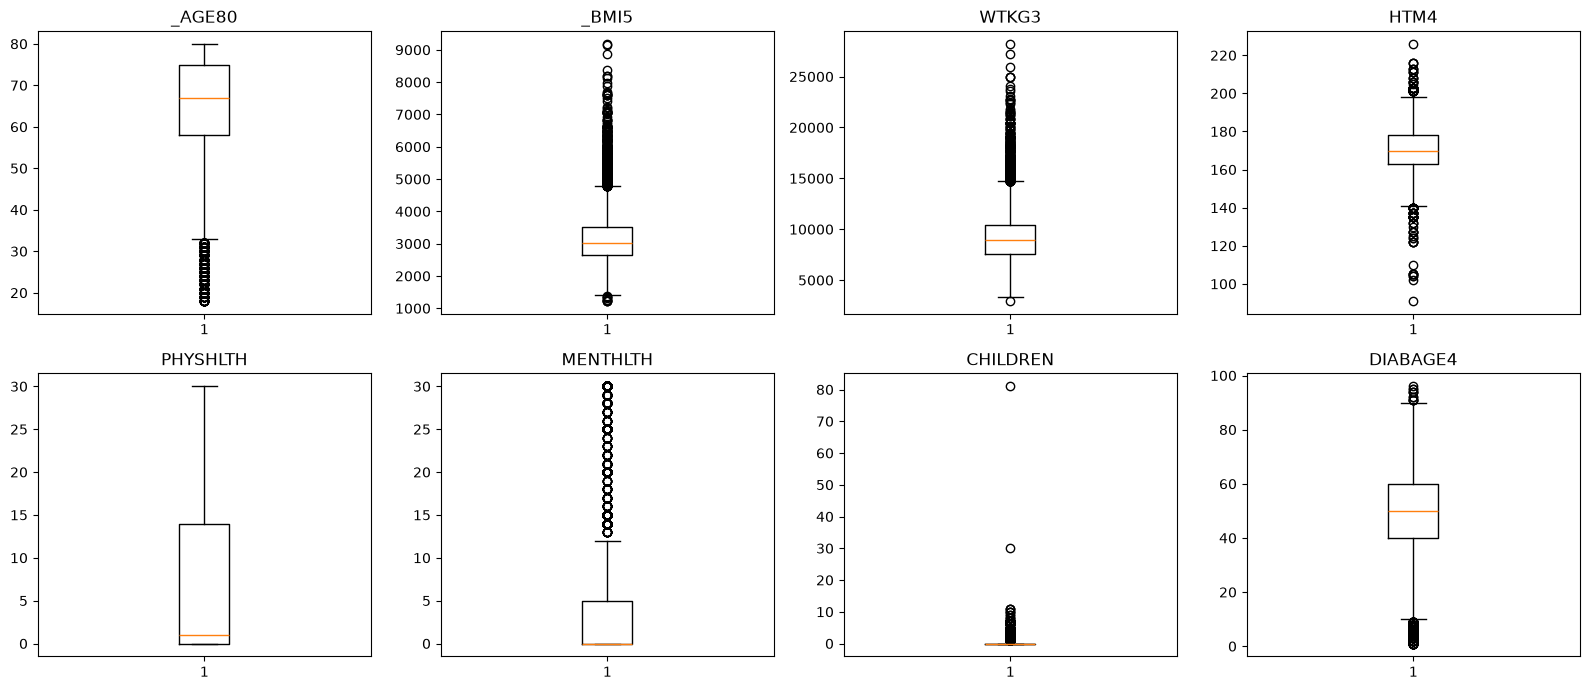

In [55]:
# %% Cek outlier (hanya fitur numerik kontinu)
import matplotlib.pyplot as plt

num_cols = ["_AGE80", "_BMI5", "WTKG3", "HTM4", "PHYSHLTH", "MENTHLTH",
            "SLEPTIM1", "_DRNKWK2", "CHILDREN", "DIABAGE4"]
num_cols = [c for c in num_cols if c in data.columns]

# %% Ringkasan outlier dengan metode IQR
rows = []
for c in num_cols:
    q1, q3 = data[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((data[c] < low) | (data[c] > high)).sum()
    rows.append({
        "fitur": c,
        "min": data[c].min(),
        "Q1": q1,
        "median": data[c].median(),
        "Q3": q3,
        "max": data[c].max(),
        "batas_bawah": round(low, 2),
        "batas_atas": round(high, 2),
        "jumlah_outlier": n_out,
        "persen_outlier": round(n_out / len(data) * 100, 2),
    })

outlier_df = pd.DataFrame(rows).sort_values("persen_outlier", ascending=False)
print(outlier_df.to_string(index=False))

# %% Visualisasi boxplot
n = len(num_cols)
ncols = 4
nrows = -(-n // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.5 * nrows))
axes = axes.flatten()

for ax, c in zip(axes, num_cols):
    ax.boxplot(data[c].dropna(), vert=True)
    ax.set_title(c)

for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

GENHLTH    -0.202703
CVDSTRK3    0.186052
_AGE80     -0.174478
DIFFWALK    0.172995
EMPLOY1    -0.164944
CHCCOPD3    0.161288
PHYSHLTH   -0.153941
CHCKDNY2    0.150087
HAVARTH4    0.113775
DIFFALON    0.106574
SEXVAR      0.106017
DEAF        0.104382
VETERAN3    0.102371
DIFFDRES    0.100541
PNEUVAC4    0.097346
PERSDOC3   -0.094834
INCOME3     0.092636
_SMOKER3    0.083511
EXERANY2   -0.077222
BLIND       0.071570
Name: _MICHD, dtype: float64


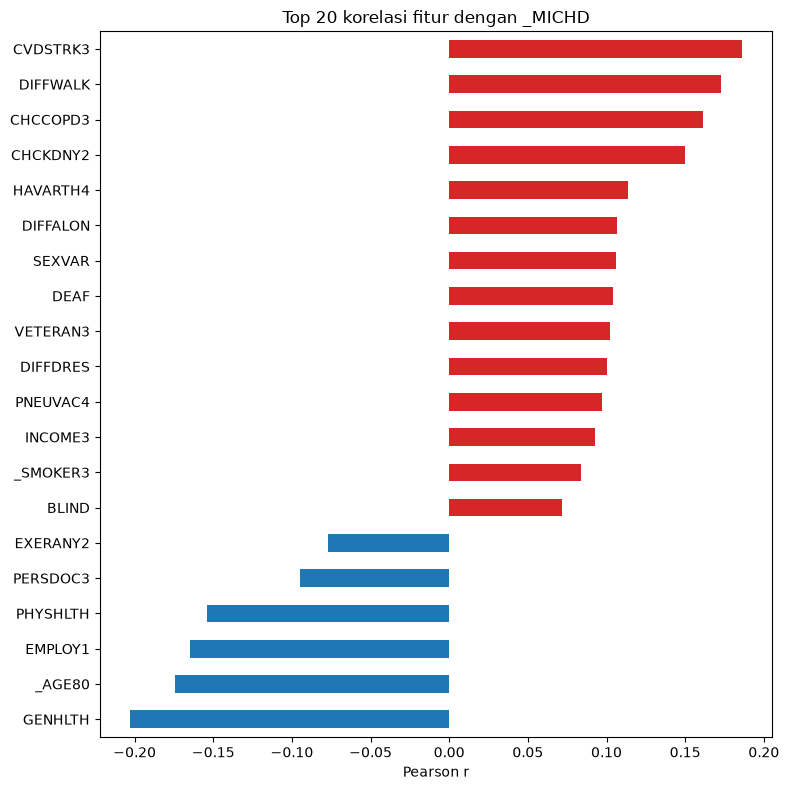

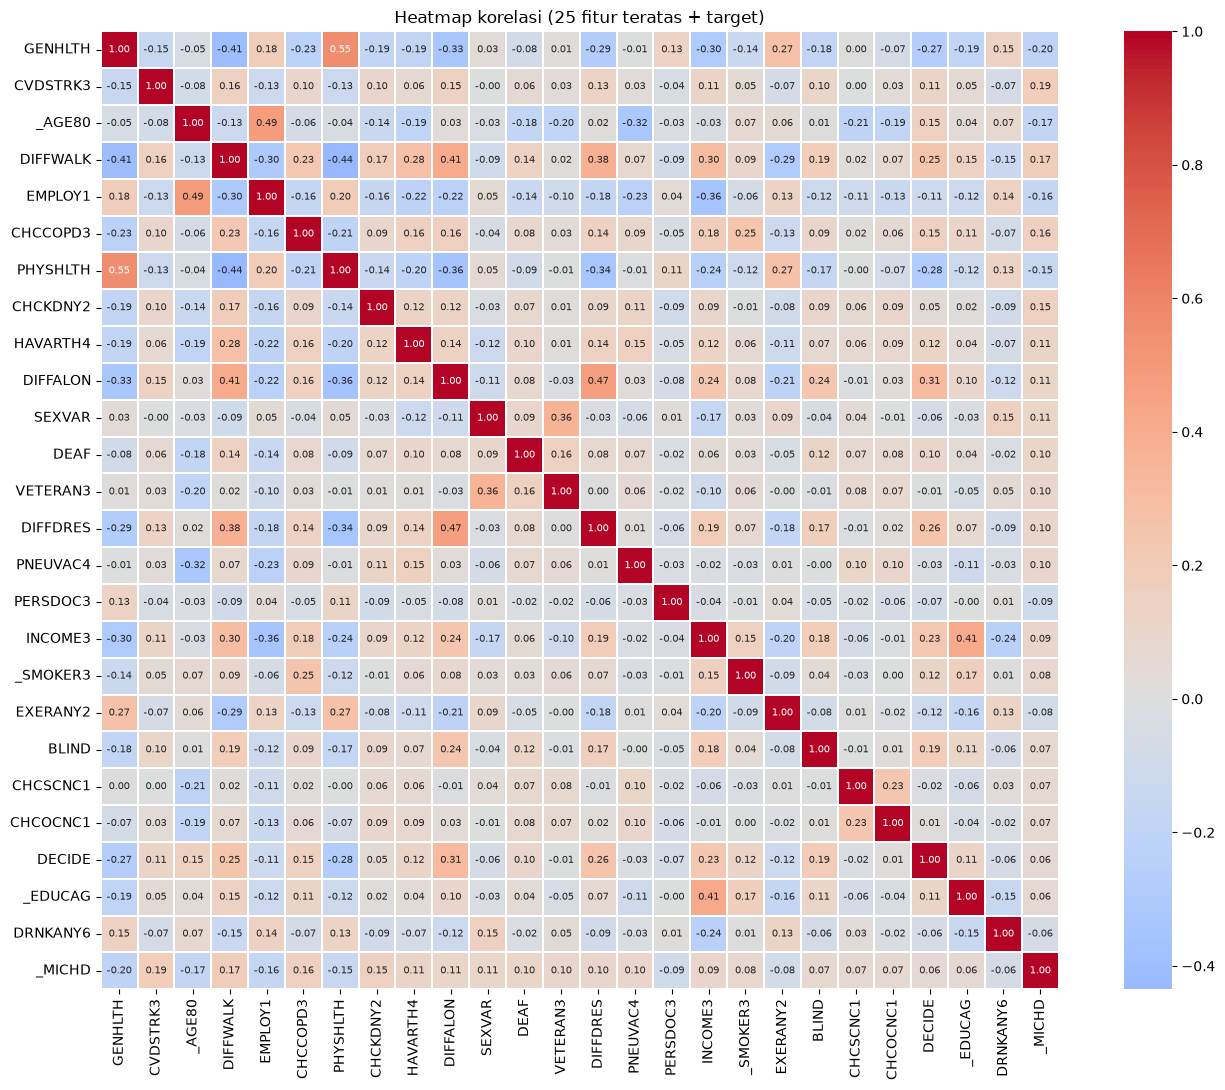

fitur_1 fitur_2        r
  _BMI5   WTKG3 0.852835


In [56]:
# %%
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Pastikan target numerik 0/1
df_corr = data.copy()
df_corr["_MICHD"] = df_corr["_MICHD"].astype(int)

corr = df_corr.corr(method="pearson", numeric_only=True)

# %%
# 1) Korelasi tiap fitur terhadap target (_MICHD)
target_corr = corr["_MICHD"].drop("_MICHD").sort_values(key=abs, ascending=False)
print(target_corr.head(20))

plt.figure(figsize=(8, 8))
top = target_corr.head(20).sort_values()
colors = ["tab:red" if v > 0 else "tab:blue" for v in top]
top.plot(kind="barh", color=colors)
plt.title("Top 20 korelasi fitur dengan _MICHD")
plt.xlabel("Pearson r")
plt.tight_layout(); plt.show()

# %%
# 2) Heatmap korelasi: 25 fitur teratas terhadap target + target
top_cols = target_corr.head(25).index.tolist() + ["_MICHD"]
plt.figure(figsize=(14, 11))
sns.heatmap(df_corr[top_cols].corr(), cmap="coolwarm", center=0,
            annot=True, fmt=".2f", annot_kws={"size": 7},
            square=True, linewidths=0.3)
plt.title("Heatmap korelasi (25 fitur teratas + target)")
plt.tight_layout(); plt.show()

# %%
# 3) Pasangan fitur dengan korelasi antar-fitur tinggi (|r| > 0.8)
feat_corr = corr.drop(index="_MICHD", columns="_MICHD")
upper = feat_corr.where(np.triu(np.ones(feat_corr.shape, dtype=bool), k=1))

high_pairs = (upper.stack()
                   .rename("r")
                   .reset_index()
                   .rename(columns={"level_0": "fitur_1", "level_1": "fitur_2"}))
high_pairs = high_pairs[high_pairs["r"].abs() > 0.8].sort_values("r", key=abs, ascending=False)
print(high_pairs.to_string(index=False))

In [57]:
# Cek value counts untuk semua fitur
for col in data.columns:
    print(f"\n{'=' * 60}")
    print(f"Fitur: {col}")
    print(f"Jumlah nilai unik: {data[col].nunique(dropna=False)}")
    print(f"{'=' * 60}")

    print(data[col].value_counts(dropna=False).to_string())


Fitur: _STATE
Jumlah nilai unik: 48
_STATE
53.0    1419
12.0    1271
17.0    1186
24.0    1158
27.0    1153
36.0    1052
55.0    1048
23.0     996
26.0     976
39.0     951
21.0     916
20.0     880
19.0     809
31.0     732
49.0     721
18.0     658
13.0     606
15.0     602
8.0      597
25.0     591
48.0     550
22.0     548
5.0      541
47.0     537
4.0      531
54.0     528
33.0     520
1.0      509
38.0     502
34.0     501
9.0      496
45.0     479
51.0     468
29.0     459
50.0     432
30.0     425
44.0     414
56.0     397
10.0     390
2.0      386
46.0     362
40.0     349
35.0     343
41.0     315
37.0     284
42.0     254
16.0     205
11.0     200

Fitur: IYEAR
Jumlah nilai unik: 2
IYEAR
2025    28571
2026     1676

Fitur: SEXVAR
Jumlah nilai unik: 2
SEXVAR
1.0    15850
2.0    14397

Fitur: _AGE80
Jumlah nilai unik: 63
_AGE80
80.0    3666
70.0    1067
65.0    1064
68.0     997
67.0     989
72.0     982
73.0     935
69.0     925
78.0     923
74.0     916
77.0     904
71.0   

In [58]:
data['CHILDREN'].value_counts()

CHILDREN
0.0     25947
1.0      2216
2.0      1290
3.0       511
4.0       185
5.0        49
6.0        19
7.0        17
10.0        3
11.0        3
8.0         3
9.0         2
81.0        1
30.0        1
Name: count, dtype: int64

In [59]:
# Konversi nilai ke satuan aktual
data["HTM4"] = data["HTM4"] / 100
data["WTKG3"] = data["WTKG3"] / 100
data["_BMI5"] = data["_BMI5"] / 100

In [60]:
data

,_STATE,IYEAR,SEXVAR,_AGE80,MARITAL,_EDUCAG,INCOME3,EMPLOY1,RENTHOM1,VETERAN3,...,DECIDE,DIFFWALK,DIFFDRES,DIFFALON,_SMOKER3,USENOW3,_RFBING6,DRNKANY6,FLUSHOT7,PNEUVAC4
3,1.0,2025,2.0,72.0,1.0,2.0,7.0,7.0,1.0,2.0,...,2.0,1.0,2.0,2.0,4.0,3.0,1.0,2.0,1.0,1.0
5,1.0,2025,1.0,64.0,1.0,4.0,7.0,8.0,1.0,2.0,...,1.0,1.0,2.0,2.0,3.0,3.0,1.0,2.0,1.0,1.0
7,1.0,2025,2.0,70.0,3.0,4.0,7.0,7.0,1.0,2.0,...,2.0,2.0,2.0,2.0,3.0,3.0,2.0,1.0,2.0,1.0
8,1.0,2025,2.0,80.0,3.0,3.0,3.0,7.0,3.0,2.0,...,1.0,1.0,1.0,1.0,4.0,3.0,1.0,2.0,2.0,1.0
9,1.0,2025,2.0,75.0,5.0,2.0,2.0,8.0,2.0,2.0,...,2.0,1.0,2.0,2.0,4.0,2.0,1.0,2.0,2.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50775,56.0,2025,2.0,65.0,2.0,4.0,6.0,7.0,1.0,2.0,...,2.0,2.0,2.0,2.0,4.0,3.0,1.0,2.0,1.0,1.0
50776,56.0,2025,1.0,65.0,1.0,4.0,10.0,7.0,1.0,2.0,...,2.0,2.0,2.0,2.0,4.0,3.0,1.0,2.0,1.0,1.0
50777,56.0,2025,1.0,80.0,1.0,3.0,8.0,7.0,1.0,1.0,...,2.0,2.0,2.0,2.0,3.0,2.0,1.0,2.0,2.0,1.0
50780,56.0,2025,2.0,64.0,5.0,4.0,7.0,1.0,1.0,2.0,...,2.0,1.0,2.0,2.0,4.0,3.0,1.0,2.0,1.0,1.0


In [61]:
for col in data.columns:
    print(f"\n{'='*50}")
    print(f"Fitur: {col}")
    print(f"Jumlah nilai unik: {data[col].nunique()}")
    print("="*50)

    print(data[col].value_counts(dropna=False))


Fitur: _STATE
Jumlah nilai unik: 48
_STATE
53.0    1419
12.0    1271
17.0    1186
24.0    1158
27.0    1153
36.0    1052
55.0    1048
23.0     996
26.0     976
39.0     951
21.0     916
20.0     880
19.0     809
31.0     732
49.0     721
18.0     658
13.0     606
15.0     602
8.0      597
25.0     591
48.0     550
22.0     548
5.0      541
47.0     537
4.0      531
54.0     528
33.0     520
1.0      509
38.0     502
34.0     501
9.0      496
45.0     479
51.0     468
29.0     459
50.0     432
30.0     425
44.0     414
56.0     397
10.0     390
2.0      386
46.0     362
40.0     349
35.0     343
41.0     315
37.0     284
42.0     254
16.0     205
11.0     200
Name: count, dtype: int64

Fitur: IYEAR
Jumlah nilai unik: 2
IYEAR
2025    28571
2026     1676
Name: count, dtype: int64

Fitur: SEXVAR
Jumlah nilai unik: 2
SEXVAR
1.0    15850
2.0    14397
Name: count, dtype: int64

Fitur: _AGE80
Jumlah nilai unik: 63
_AGE80
80.0    3666
70.0    1067
65.0    1064
68.0     997
67.0     989
72.0   

In [62]:
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Helper
# ------------------------------------------------------------
def to_binary(df, col, yes, no):
    """Petakan yes -> 1, no -> 0. Semua kode lain (7, 9, dst) jadi NaN."""
    df[col] = df[col].map({yes: 1, no: 0})

def onehot(df, col, invalid=(7, 9), prefix=None):
    """
    1) Kode invalid (Don't know / Refused) -> NaN
    2) One-hot encoding
    3) Baris yang aslinya NaN tetap NaN di semua kolom dummy
       (bukan 0 semua)
    """
    prefix = prefix or col
    s = df[col].replace(list(invalid), np.nan).astype("Int64")
    mask = s.isna()
    dummies = pd.get_dummies(s, prefix=prefix, dtype=float)
    dummies[mask] = np.nan
    return pd.concat([df.drop(columns=col), dummies], axis=1)

# ------------------------------------------------------------
# BINARY (1 = Yes -> 1, 2 = No -> 0)
# ------------------------------------------------------------
# SEXVAR: 1 = Male, 2 = Female  ->  Male = 0, Female = 1
to_binary(data, "SEXVAR", yes=2, no=1)

# VETERAN3: 1 = Yes, 2 = No
to_binary(data, "VETERAN3", yes=1, no=2)

# _URBSTAT: 1 = Urban, 2 = Rural  ->  Urban = 1, Rural = 0
to_binary(data, "_URBSTAT", yes=1, no=2)

# FLUSHOT7, PNEUVAC4: 1 = Yes, 2 = No
for col in ["FLUSHOT7", "PNEUVAC4"]:
    to_binary(data, col, yes=1, no=2)

# _RFBING6: 1 = No, 2 = Yes, 9 = DK/Refused  (KEBALIKAN dari yang lain!)
to_binary(data, "_RFBING6", yes=2, no=1)

# Semua yang kodenya 1 = Yes, 2 = No
binary_features = [
    "MEDCOST1", "EXERANY2", "CVDSTRK3", "CHCSCNC1", "CHCOCNC1",
    "CHCCOPD3", "ADDEPEV3", "CHCKDNY2", "HAVARTH4",
    "DEAF", "BLIND", "DECIDE", "DIFFWALK", "DIFFDRES", "DIFFALON",
]
for col in binary_features:
    to_binary(data, col, yes=1, no=2)

# ------------------------------------------------------------
# ORDINAL
# ------------------------------------------------------------
# GENHLTH: 1 = Excellent ... 5 = Poor; 7, 9 -> NaN
data["GENHLTH"] = data["GENHLTH"].replace([7, 9], np.nan)

# ------------------------------------------------------------
# ONE-HOT (nominal)
# ------------------------------------------------------------
data = onehot(data, "MARITAL")
data = onehot(data, "EMPLOY1",   invalid=(9,))
data = onehot(data, "RENTHOM1",  invalid=(7, 9))
data = onehot(data, "_IMPRACE",  invalid=())          # 1-6, tidak ada kode invalid
data = onehot(data, "PERSDOC3",  invalid=(7, 9))
data = onehot(data, "_ASTHMS1",  invalid=(9,))
data = onehot(data, "_SMOKER3",  invalid=(9,))
data = onehot(data, "USENOW3",   invalid=(7, 9))

# ------------------------------------------------------------
# VERIFIKASI
# ------------------------------------------------------------
all_binary = (
    ["SEXVAR", "VETERAN3", "_URBSTAT", "FLUSHOT7", "PNEUVAC4", "_RFBING6"]
    + binary_features
)
for col in all_binary:
    vals = set(data[col].dropna().unique())
    assert vals <= {0, 1}, f"{col} punya nilai tak terduga: {vals}"
    print(f"{col:10s} ->", data[col].value_counts(dropna=False).to_dict())

SEXVAR     -> {0: 15850, 1: 14397}
VETERAN3   -> {0: 25109, 1: 5138}
_URBSTAT   -> {1: 25504, 0: 4743}
FLUSHOT7   -> {1: 17240, 0: 13007}
PNEUVAC4   -> {1: 19969, 0: 10278}
_RFBING6   -> {0: 28427, 1: 1820}
MEDCOST1   -> {0: 27582, 1: 2665}
EXERANY2   -> {1: 19582, 0: 10665}
CVDSTRK3   -> {0: 27306, 1: 2941}
CHCSCNC1   -> {0: 26832, 1: 3415}
CHCOCNC1   -> {0: 24598, 1: 5649}
CHCCOPD3   -> {0: 25865, 1: 4382}
ADDEPEV3   -> {0: 22285, 1: 7962}
CHCKDNY2   -> {0: 25589, 1: 4658}
HAVARTH4   -> {1: 16044, 0: 14203}
DEAF       -> {0: 25751, 1: 4496}
BLIND      -> {0: 27474, 1: 2773}
DECIDE     -> {0: 25808, 1: 4439}
DIFFWALK   -> {0: 20410, 1: 9837}
DIFFDRES   -> {0: 27726, 1: 2521}
DIFFALON   -> {0: 26263, 1: 3984}


In [63]:
data.info()
data["_MICHD"] = data["_MICHD"].map({1.0: 1, 2.0: 0}).astype(int)

<class 'pandas.DataFrame'>
Index: 30247 entries, 3 to 50782
Data columns (total 74 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   _STATE      30247 non-null  float64
 1   IYEAR       30247 non-null  int64  
 2   SEXVAR      30247 non-null  int64  
 3   _AGE80      30247 non-null  float64
 4   _EDUCAG     30247 non-null  float64
 5   INCOME3     30247 non-null  float64
 6   VETERAN3    30247 non-null  int64  
 7   CHILDREN    30247 non-null  float64
 8   _URBSTAT    30247 non-null  int64  
 9   _BMI5       30247 non-null  float64
 10  DIABETE4    30247 non-null  float64
 11  WTKG3       30247 non-null  float64
 12  HTM4        30247 non-null  float64
 13  MEDCOST1    30247 non-null  int64  
 14  CHECKUP1    30247 non-null  float64
 15  GENHLTH     30247 non-null  float64
 16  PHYSHLTH    30247 non-null  float64
 17  MENTHLTH    30247 non-null  float64
 18  EXERANY2    30247 non-null  int64  
 19  CVDSTRK3    30247 non-null  int64  
 20  

In [64]:
# 1 = minum alkohol dalam 30 hari terakhir, 0 = tidak
data['DRNKANY6'] = data['DRNKANY6'].map({1.0: 1, 2.0: 0})

print(data['DRNKANY6'].value_counts(dropna=False))

DRNKANY6
0    19407
1    10840
Name: count, dtype: int64


In [65]:
data = data[(data['CHILDREN'] < 30) | (data['CHILDREN'].isna())]
data = data.drop(columns=['WTKG3','HTM4'])

In [66]:
data['CHILDREN'].value_counts()

CHILDREN
0.0     25947
1.0      2216
2.0      1290
3.0       511
4.0       185
5.0        49
6.0        19
7.0        17
10.0        3
11.0        3
8.0         3
9.0         2
Name: count, dtype: int64

In [67]:
data.to_csv(r"C:\Users\s2\Documents\RKI\BRFSS\brfss2025_diabetes.csv", index=False)

In [68]:
data['_MICHD'].value_counts()

_MICHD
0    23891
1     6354
Name: count, dtype: int64

In [69]:
data['_MICHD'].value_counts()

_MICHD
0    23891
1     6354
Name: count, dtype: int64

In [70]:
data.info()

<class 'pandas.DataFrame'>
Index: 30245 entries, 3 to 50782
Data columns (total 72 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   _STATE      30245 non-null  float64
 1   IYEAR       30245 non-null  int64  
 2   SEXVAR      30245 non-null  int64  
 3   _AGE80      30245 non-null  float64
 4   _EDUCAG     30245 non-null  float64
 5   INCOME3     30245 non-null  float64
 6   VETERAN3    30245 non-null  int64  
 7   CHILDREN    30245 non-null  float64
 8   _URBSTAT    30245 non-null  int64  
 9   _BMI5       30245 non-null  float64
 10  DIABETE4    30245 non-null  float64
 11  MEDCOST1    30245 non-null  int64  
 12  CHECKUP1    30245 non-null  float64
 13  GENHLTH     30245 non-null  float64
 14  PHYSHLTH    30245 non-null  float64
 15  MENTHLTH    30245 non-null  float64
 16  EXERANY2    30245 non-null  int64  
 17  CVDSTRK3    30245 non-null  int64  
 18  CHCSCNC1    30245 non-null  int64  
 19  CHCOCNC1    30245 non-null  int64  
 20  